# Assignment 1 | SO-101 시연 데이터셋 수집 및 분석

**학번:** 2021136066  
**이름:** 손건  
**소속:** 컴퓨터공학부  
**로봇:** SO-101 (Leader / Follower)  
**과제:** 물체를 집어 지정된 위치에 내려놓는 태스크의 시연 데이터를 수집하고 분석한다.

- **Hugging Face 데이터셋:** [`rimur01/so101-assignment1-50-new`](https://huggingface.co/datasets/rimur01/so101-assignment1-50-new)
- **수집 개수:** 총 **50개 에피소드** (0~49). 수집 후 Windows 로컬 `meta/info.json`에서 `total_episodes: 50`을 확인하였다.
- **기록 설정:** 두 대의 OpenCV 카메라(`cam0`, `cam1`), 640×480, MJPG, 15 FPS, 에피소드당 최대 20초.

> **검증 범위:** 사용자 터미널에서 확인된 것은 **로컬 메타데이터의 50개 저장**이다. Hub에 실제 50개가 공개 업로드되었는지, 전체 영상이 정상이며 태스크에 성공했는지는 아래 코드 실행과 개별 영상 검수를 통해 **별도로 확인**한다. 검수 전인 에피소드의 결과를 임의로 성공(O) 처리하지 않는다.

이 노트북에는 데이터셋 공개 여부 점검, 메타데이터 분석, 에피소드 길이 그래프, 관절 state/action 그래프, 카메라 샘플, 50개 영상 검수표, 회고 및 최종 체크리스트가 포함되어 있다.


## 0. 제출자 및 데이터셋 정보

아래 정보는 실제 수집에 사용한 설정과 일치한다. 로컬 분석은 Windows의 `C:/lerobot_data/so101-assignment1-50-new` 폴더를 사용하며, 업로드 상태 확인은 Hugging Face Hub API를 사용한다.


In [2]:
STUDENT_ID = "2021136066"
NAME = "손건"
DEPARTMENT = "컴퓨터공학부"
HF_USER = "rimur01"
DATASET = "rimur01/so101-assignment1-50-new"
LOCAL_ROOT = "C:/lerobot_data/so101-assignment1-50-new"
TASK = "Pick up an object and place it in a target area"
EXPECTED_EPISODES = 50
FPS_TARGET = 15
CAMERAS = {"cam0": 0, "cam1": 1}

print(f"제출자: {DEPARTMENT} {STUDENT_ID} {NAME}")
print("태스크:", TASK)
print("로컬 경로:", LOCAL_ROOT)
print("데이터셋:", f"https://huggingface.co/datasets/{DATASET}")


제출자: 컴퓨터공학부 2021136066 손건
태스크: Pick up an object and place it in a target area
로컬 경로: C:/lerobot_data/so101-assignment1-50-new
데이터셋: https://huggingface.co/datasets/rimur01/so101-assignment1-50-new


In [3]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from huggingface_hub import HfApi, hf_hub_download
from IPython.display import display

api = HfApi()
root = Path(LOCAL_ROOT)
repo_files = []
is_public = False
hub_reachable = False

try:
    hub_info = api.repo_info(repo_id=DATASET, repo_type="dataset")
    is_public = not bool(getattr(hub_info, "private", True))
    repo_files = api.list_repo_files(repo_id=DATASET, repo_type="dataset")
    hub_reachable = True
    print("Hub 저장소 조회: 성공")
    print("공개 여부:", "Public" if is_public else "Private")
    print("Hub 파일 수:", len(repo_files))
except Exception as exc:
    print("Hub 저장소 조회: 확인 불가 —", type(exc).__name__, str(exc)[:160])
    print("로컬 데이터는 계속 분석할 수 있으나 업로드 검증은 아직 미완료입니다.")

print("로컬 데이터 폴더:", "존재" if root.is_dir() else "현재 PC에 없음")


Hub 저장소 조회: 성공
공개 여부: Public
Hub 파일 수: 13
로컬 데이터 폴더: 존재


## Hub 공개 여부 및 업로드 상태 검사

로컬의 50개 에피소드 저장과 Hub 공개 업로드는 별개의 검증 항목이다. 아래 코드는 **실행 시점**에 원격 저장소를 조회한다. 네트워크 장애 또는 미업로드 상태에서는 통과로 표시하지 않는다.


## 1. 태스크 정의 및 수집 환경

### 1-1. 태스크 정의

- **태스크:** 테이블 위 물체를 로봇 그리퍼로 집어 지정한 목표 영역으로 이동한 후 놓는 Pick & Place 작업.
- **성공 조건:** 물체를 안정적으로 집고 이동시켜 목표 영역에 놓으며, 영상에 동작의 시작과 끝이 모두 담겨 있어야 한다.
- **태스크 문자열:** `Pick up an object and place it in a target area`
- **기록 단위:** 시연 1회 = 에피소드 1개, 총 50개 (인덱스 0~49).

### 1-2. 하드웨어·소프트웨어 환경

| 항목 | 사용 설정 |
|---|---|
| 운영체제 | Windows 11 |
| 실행 환경 | Conda `C:/lerobot-envs/lerobot312` |
| 로봇 | SO-101 Leader / SO-101 Follower |
| Leader 연결 | COM7, `my_leader` |
| Follower 연결 | COM6, `my_follower` |
| 카메라 | USB 카메라 0번 및 1번 (`cam0`, `cam1`) |
| 카메라 설정 | OpenCV DSHOW(700), 640×480, MJPG, 15 FPS |
| 데이터 FPS | 15 |
| 한 에피소드 녹화 | 최대 20초 |
| 에피소드 간 준비시간 | 8초 |
| 데이터셋 경로 | `C:/lerobot_data/so101-assignment1-50-new` |
| Hub repo_id | `rimur01/so101-assignment1-50-new` |

### 1-3. 수집 과정 요약

먼저 로봇 관절을 보정한 후 Leader를 이용해 Follower를 직접 조종하였다. USB 시리얼 포트는 케이블 분리 전후의 COM 포트 목록을 비교해 확인하였다. 카메라 확인 과정에서는 처음 사용했던 2번 인덱스가 노트북 내장 카메라임을 발견하여 실제 USB 카메라인 **0번과 1번**으로 수정하였다. 두 카메라를 동시에 열 때 발생하던 오류는 영상의 **해상도 → FPS → MJPG** 설정 순서로 확인해 정상 프레임 수신을 검증하였다. 이후 에피소드 0번을 먼저 기록하고, `--resume=true`로 49개를 추가하여 로컬 메타데이터 기준 총 50개를 확보하였다.

**참고:** 아래 명령어는 수집 절차를 재현하기 위한 기록이다. **이미 50개가 있는 폴더에 다시 실행하지 않는다.**


In [4]:
CAMERA_CONFIG = (
    "{ cam0: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 15, fourcc: MJPG, backend: 700}, "
    "cam1: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 15, fourcc: MJPG, backend: 700}}"
)
RECORD_BASE = (
    "lerobot-record "
    "--robot.type=so101_follower --robot.port=COM6 --robot.id=my_follower "
    f'--robot.cameras="{CAMERA_CONFIG}" '
    "--teleop.type=so101_leader --teleop.port=COM7 --teleop.id=my_leader "
    "--display_data=false "
    f"--dataset.repo_id={DATASET} --dataset.root={LOCAL_ROOT} "
    "--dataset.fps=15 --dataset.episode_time_s=20 --dataset.reset_time_s=8 "
    f'--dataset.single_task="{TASK}" '
    "--dataset.push_to_hub=true --dataset.private=false "
)
RECORD_FIRST = RECORD_BASE + "--dataset.num_episodes=1"
RECORD_REMAINING = RECORD_BASE + "--dataset.num_episodes=49 --resume=true"
print("최초 1개 수집 명령 (기록용):\n", RECORD_FIRST)
print("\n나머지 49개 추가 수집 명령 (기록용):\n", RECORD_REMAINING)
print("\n주의: 총 50개 수집이 끝났다면 두 명령 모두 재실행하지 않습니다.")


최초 1개 수집 명령 (기록용):
 lerobot-record --robot.type=so101_follower --robot.port=COM6 --robot.id=my_follower --robot.cameras="{ cam0: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 15, fourcc: MJPG, backend: 700}, cam1: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 15, fourcc: MJPG, backend: 700}}" --teleop.type=so101_leader --teleop.port=COM7 --teleop.id=my_leader --display_data=false --dataset.repo_id=rimur01/so101-assignment1-50-new --dataset.root=C:/lerobot_data/so101-assignment1-50-new --dataset.fps=15 --dataset.episode_time_s=20 --dataset.reset_time_s=8 --dataset.single_task="Pick up an object and place it in a target area" --dataset.push_to_hub=true --dataset.private=false --dataset.num_episodes=1

나머지 49개 추가 수집 명령 (기록용):
 lerobot-record --robot.type=so101_follower --robot.port=COM6 --robot.id=my_follower --robot.cameras="{ cam0: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 15, fourcc: MJPG, backend: 700}, cam1: {type: opencv, index_

### 1-4. 카메라 문제 진단 기록

초기에는 OpenCV 카메라 0번과 2번을 사용했으나, 2번은 노트북 내장 카메라였다. 0번과 1번 USB 카메라는 단독으로는 정상적으로 열렸지만, 동시에 열 때 두 번째 카메라 연결이 실패하였다. 이후 영상 형식을 **MJPG**로 지정하고 해상도·FPS·영상 형식 설정 순서를 변경한 테스트에서 두 카메라 모두 `OPEN=True`, `FRAME=True`, `FORMAT=MJPG`, `FPS≈15`를 확인하였다.

수집 과정에서 한글이 포함된 Windows 사용자 폴더 대신 영문 경로인 `C:/lerobot_data/`를 사용했다. 최종 카메라 설정은 `cam0`(인덱스 0), `cam1`(인덱스 1)이다. **두 카메라의 실제 화질과 최종 데이터에 저장된 영상 품질은 영상 검수에서 별도 확인한다.**


## 2. 데이터셋 메타데이터 확인

사용자 터미널에서 `meta/info.json`의 `total_episodes=50`을 확인했다. 아래 코드는 노트북을 **실행하는 PC에서 원격 또는 로컬 메타데이터를 다시 읽어**, 실제 분석에 사용할 값을 채운다. 네트워크가 안 되더라도 수집 PC에 로컬 데이터가 있다면 분석할 수 있다.


In [5]:
def read_json_file(path):
    with open(path, "r", encoding="utf-8") as handle:
        return json.load(handle)

info = None
info_source = None
local_info_path = root / "meta" / "info.json"

# 공개 업로드 검증을 위해 가능하면 Hub 정보를 우선 읽습니다.
if hub_reachable:
    try:
        remote_info = hf_hub_download(repo_id=DATASET, filename="meta/info.json", repo_type="dataset", force_download=True)
        info = read_json_file(remote_info)
        info_source = "Hugging Face Hub"
    except Exception as exc:
        print("Hub meta/info.json 조회 실패:", type(exc).__name__, exc)

if info is None and local_info_path.exists():
    info = read_json_file(local_info_path)
    info_source = "Windows 로컬 저장소 (Hub 업로드 검증 아님)"

fps = (info or {}).get("fps", FPS_TARGET)
n_ep = (info or {}).get("total_episodes")
camera_keys = [k for k in (info or {}).get("features", {}) if k.startswith("observation.images.")]
print("메타데이터 원본:", info_source or "읽지 못함")
print("총 에피소드 수:", n_ep)
print("목표 에피소드 수:", EXPECTED_EPISODES)
print("FPS:", fps)
print("총 프레임:", (info or {}).get("total_frames"))
print("카메라:", camera_keys)
print("카메라 설정 일치:", set(camera_keys) >= {"observation.images.cam0", "observation.images.cam1"})
print("에피소드 개수 확인:", n_ep == EXPECTED_EPISODES)
if info is None:
    print("수집 PC의 로컬 폴더를 확인하거나, Hugging Face 업로드 완료 후 다시 실행하세요.")


info.json:   0%|          | 0.00/3.81k [00:00<?, ?B/s]

메타데이터 원본: Hugging Face Hub
총 에피소드 수: 50
목표 에피소드 수: 50
FPS: 15
총 프레임: 15000
카메라: ['observation.images.cam0', 'observation.images.cam1']
카메라 설정 일치: True
에피소드 개수 확인: True


C:\Users\손건\AppData\Local\Programs\Python\Python310\lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\손건\.cache\huggingface\hub\datasets--rimur01--so101-assignment1-50-new. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


## 2-1. 에피소드별 길이 및 태스크 확인

메타데이터의 에피소드 인덱스, 프레임 길이, 태스크 종류를 점검한다. LeRobot v3 데이터셋은 `meta/episodes/*.parquet`, 다른 버전은 `meta/episodes.jsonl` 구조일 수 있다. 아래 코드는 로컬 파일이 있으면 이를 우선 사용한다.


In [6]:
ep_df = None
lengths = None
task_set = set()
meta_source = None

try:
    local_pq_files = sorted((root / "meta" / "episodes").rglob("*.parquet")) if root.is_dir() else []
    local_jsonl = root / "meta" / "episodes.jsonl"
    if local_pq_files:
        ep_df = pd.concat([pq.read_table(str(path)).to_pandas() for path in local_pq_files], ignore_index=True)
        meta_source = "로컬 Parquet"
    elif local_jsonl.exists():
        ep_df = pd.read_json(local_jsonl, lines=True)
        meta_source = "로컬 JSONL"
    elif hub_reachable:
        remote_pq = sorted(f for f in repo_files if f.startswith("meta/episodes/") and f.endswith(".parquet"))
        if remote_pq:
            ep_df = pd.concat([
                pq.read_table(hf_hub_download(repo_id=DATASET, filename=f, repo_type="dataset")).to_pandas()
                for f in remote_pq
            ], ignore_index=True)
            meta_source = "Hub Parquet"
        elif "meta/episodes.jsonl" in repo_files:
            file = hf_hub_download(repo_id=DATASET, filename="meta/episodes.jsonl", repo_type="dataset")
            ep_df = pd.read_json(file, lines=True)
            meta_source = "Hub JSONL"
except Exception as exc:
    print("에피소드 메타데이터 로딩 실패:", type(exc).__name__, exc)

print("에피소드 메타데이터 소스:", meta_source or "없음")
if ep_df is not None:
    print("에피소드 메타 컬럼:", ep_df.columns.tolist())

if ep_df is not None and {"episode_index", "length"}.issubset(ep_df.columns):
    ep_df = ep_df.sort_values("episode_index").reset_index(drop=True)
    lengths = ep_df[["episode_index", "length"]].copy()
    lengths["seconds"] = pd.to_numeric(lengths["length"], errors="coerce") / float(fps or 15)
    median_len = lengths["length"].median()
    lengths["flag"] = lengths["length"].apply(
        lambda v: "짧음 의심" if v < 0.5 * median_len else ("김 의심" if v > 2 * median_len else "일반 범위")
    )
    indices = ep_df["episode_index"].astype(int).tolist()
    print("인덱스 0~49 연속성:", indices == list(range(EXPECTED_EPISODES)))
    print("에피소드 메타 행 수:", len(ep_df))
    print("평균 길이(초):", round(lengths["seconds"].mean(), 2))
    print("최소/최대 길이(초):", round(lengths["seconds"].min(), 2), round(lengths["seconds"].max(), 2))
    print("길이 이상 의심 번호:", lengths.loc[lengths["flag"] != "일반 범위", "episode_index"].tolist())
else:
    print("에피소드별 길이를 확인할 데이터가 없습니다. 데이터셋의 meta/episodes 파일을 확인하세요.")

# 태스크 문장은 별도의 meta/tasks.jsonl 또는 meta/tasks.parquet 파일에 저장될 수 있습니다.
try:
    local_tasks_jsonl = root / "meta" / "tasks.jsonl"
    local_tasks_parquet = root / "meta" / "tasks.parquet"
    task_table = None
    if local_tasks_parquet.exists():
        task_table = pq.read_table(str(local_tasks_parquet)).to_pandas()
    elif local_tasks_jsonl.exists():
        task_table = pd.read_json(local_tasks_jsonl, lines=True)
    elif hub_reachable and "meta/tasks.parquet" in repo_files:
        task_table = pq.read_table(hf_hub_download(repo_id=DATASET, filename="meta/tasks.parquet", repo_type="dataset")).to_pandas()
    elif hub_reachable and "meta/tasks.jsonl" in repo_files:
        task_table = pd.read_json(hf_hub_download(repo_id=DATASET, filename="meta/tasks.jsonl", repo_type="dataset"), lines=True)
    if task_table is not None:
        print("태스크 메타데이터 컬럼:", task_table.columns.tolist())
        if "task" in task_table.columns:
            task_set = {str(t) for t in task_table["task"].dropna()}
    print("태스크 문자열:", task_set or "확인 불가")
    print("태스크 설정 일치:", task_set == {TASK} if task_set else "미확인")
except Exception as exc:
    print("태스크 메타데이터 확인 실패:", type(exc).__name__, exc)


에피소드 메타데이터 소스: 로컬 Parquet
에피소드 메타 컬럼: ['episode_index', 'tasks', 'length', 'data/chunk_index', 'data/file_index', 'dataset_from_index', 'dataset_to_index', 'videos/observation.images.cam0/chunk_index', 'videos/observation.images.cam0/file_index', 'videos/observation.images.cam0/from_timestamp', 'videos/observation.images.cam0/to_timestamp', 'videos/observation.images.cam1/chunk_index', 'videos/observation.images.cam1/file_index', 'videos/observation.images.cam1/from_timestamp', 'videos/observation.images.cam1/to_timestamp', 'stats/action/min', 'stats/action/max', 'stats/action/mean', 'stats/action/std', 'stats/action/count', 'stats/action/q01', 'stats/action/q10', 'stats/action/q50', 'stats/action/q90', 'stats/action/q99', 'stats/observation.state/min', 'stats/observation.state/max', 'stats/observation.state/mean', 'stats/observation.state/std', 'stats/observation.state/count', 'stats/observation.state/q01', 'stats/observation.state/q10', 'stats/observation.state/q50', 'stats/observati

## 2-2. 에피소드 길이 그래프

길이가 매우 짧거나 긴 에피소드는 잘림, 중단, 불필요하게 긴 정지일 수 있으므로 웹 뷰어에서 우선 확인합니다. 그래프만으로 성공 여부를 판정하지 마세요.


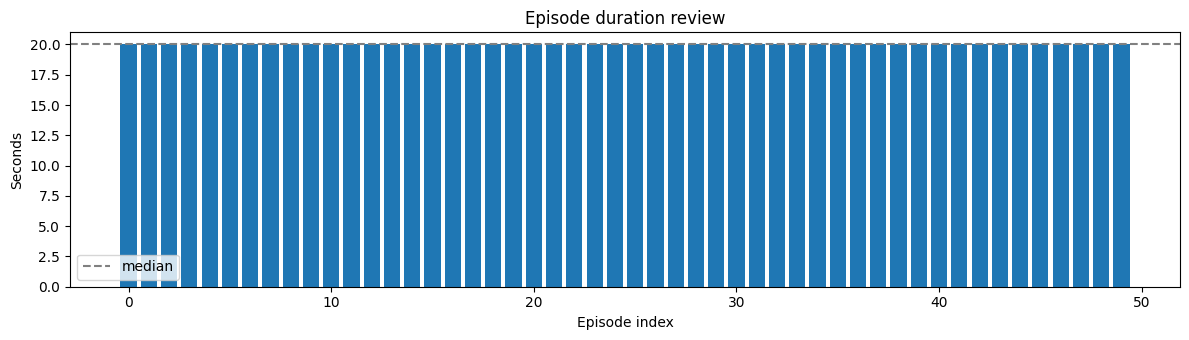

길이 이상 의심 에피소드: 없음


In [7]:
if lengths is not None and not lengths.empty:
    color_map = {"짧음 의심": "tab:red", "김 의심": "tab:orange", "일반 범위": "tab:blue"}
    plt.figure(figsize=(12, 3.5))
    plt.bar(lengths["episode_index"], lengths["seconds"], color=lengths["flag"].map(color_map))
    plt.axhline(lengths["seconds"].median(), linestyle="--", color="gray", label="median")
    plt.xlabel("Episode index")
    plt.ylabel("Seconds")
    plt.title("Episode duration review")
    plt.legend()
    plt.tight_layout()
    plt.show()
    print("길이 이상 의심 에피소드:", lengths.loc[lengths["flag"] != "일반 범위", "episode_index"].tolist() or "없음")
else:
    print("길이 그래프를 그릴 데이터가 없습니다.")


## 2-3. 관절 상태(state)와 행동(action) 시계열 그래프

에피소드 0의 state/action 값을 시간축으로 표시하여 실제 조작 궤적의 변화를 확인한다. **그래프에서 값이 변하더라도 물체 집기 성공을 의미하지는 않는다.** 성공 여부는 영상을 통해 검수한다.


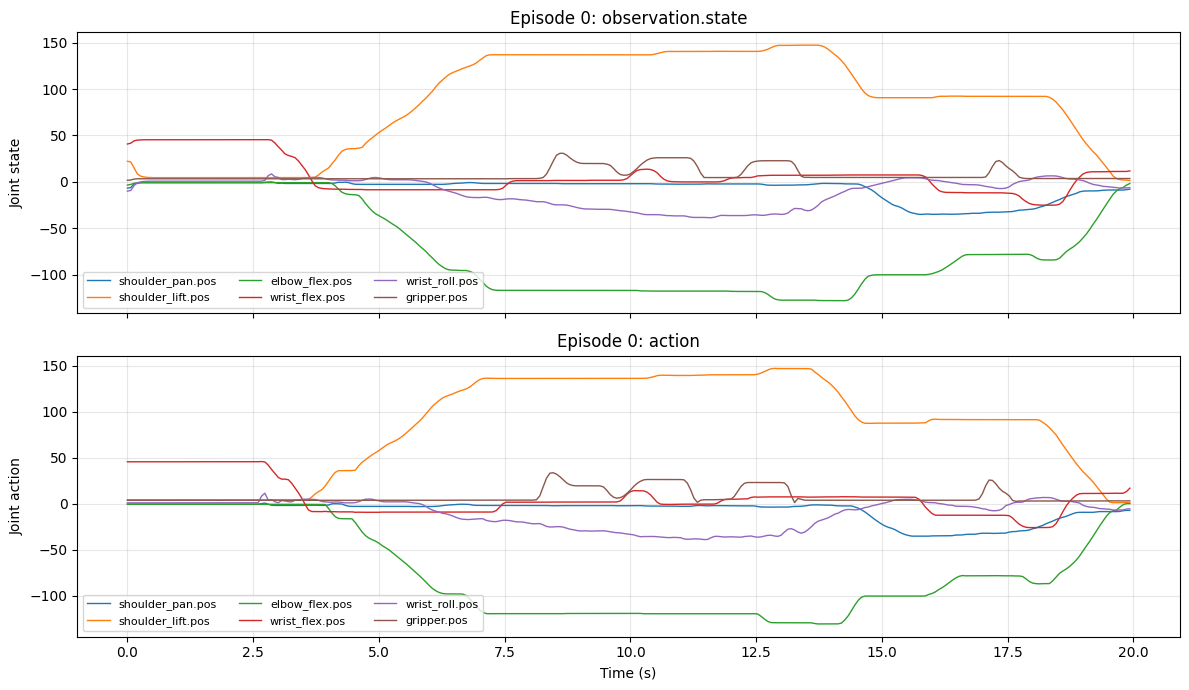

분석 파일: 로컬: C:\lerobot_data\so101-assignment1-50-new\data\chunk-000\file-000.parquet
표본 프레임 수: 300


In [8]:
# 필요한 에피소드 하나만 읽어 분석한다. 대용량 데이터 전체를 메모리에 올리지 않는다.
PLOT_EPISODE = 0
plot_df = None
parquet_source = None

try:
    data_files_local = sorted((root / "data").rglob("*.parquet")) if root.is_dir() else []
    if data_files_local:
        for filename in data_files_local:
            table = pq.read_table(str(filename))
            frame_df = table.to_pandas()
            if "episode_index" in frame_df.columns and (frame_df["episode_index"] == PLOT_EPISODE).any():
                plot_df = frame_df.loc[frame_df["episode_index"] == PLOT_EPISODE].copy()
                parquet_source = "로컬: " + str(filename)
                break
    elif hub_reachable:
        data_files_remote = sorted(f for f in repo_files if f.startswith("data/") and f.endswith(".parquet"))
        for filename in data_files_remote:
            downloaded = hf_hub_download(repo_id=DATASET, filename=filename, repo_type="dataset")
            frame_df = pq.read_table(downloaded).to_pandas()
            if "episode_index" in frame_df.columns and (frame_df["episode_index"] == PLOT_EPISODE).any():
                plot_df = frame_df.loc[frame_df["episode_index"] == PLOT_EPISODE].copy()
                parquet_source = "Hub: " + filename
                break
except Exception as exc:
    print("state/action 로드 실패:", type(exc).__name__, exc)


def values_as_matrix(series):
    rows = [np.asarray(x, dtype=float).reshape(-1) for x in series]
    return np.stack(rows) if rows else np.empty((0, 0))


def joint_names(feature_key, count):
    metadata_names = (info or {}).get("features", {}).get(feature_key, {}).get("names", [])
    if isinstance(metadata_names, list) and len(metadata_names) == count and all(isinstance(t, str) for t in metadata_names):
        return metadata_names
    fallback = ["shoulder_pan", "shoulder_lift", "elbow_flex", "wrist_flex", "wrist_roll", "gripper"]
    return fallback[:count] if count <= 6 else [f"joint_{i}" for i in range(count)]

if plot_df is None:
    print(f"에피소드 {PLOT_EPISODE}의 Parquet를 찾지 못했습니다. 업로드/로컬 경로를 확인하세요.")
if plot_df is not None:
    if not {"observation.state", "action"}.issubset(plot_df.columns):
        print("state/action 컬럼이 없습니다:", plot_df.columns.tolist())
    else:
        state = values_as_matrix(plot_df["observation.state"])
        action = values_as_matrix(plot_df["action"])
        frame_idx = plot_df["frame_index"].to_numpy() if "frame_index" in plot_df.columns else np.arange(len(plot_df))
        t = frame_idx / float(fps or FPS_TARGET)
        fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
        for k, name in enumerate(joint_names("observation.state", state.shape[1])):
            ax[0].plot(t, state[:, k], label=name, linewidth=1)
        for k, name in enumerate(joint_names("action", action.shape[1])):
            ax[1].plot(t, action[:, k], label=name, linewidth=1)
        ax[0].set(title=f"Episode {PLOT_EPISODE}: observation.state", ylabel="Joint state")
        ax[1].set(title=f"Episode {PLOT_EPISODE}: action", xlabel="Time (s)", ylabel="Joint action")
        for axis in ax:
            axis.legend(ncol=3, fontsize=8)
            axis.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
        print("분석 파일:", parquet_source)
        print("표본 프레임 수:", len(plot_df))


## 2-4. 카메라 프레임 점검

에피소드 0의 카메라 프레임을 확인한다. 실제 과제에서는 **`cam0`과 `cam1`**만 사용하였으며, 노트북 내장 카메라(당시 인덱스 2)는 제외하였다. 한 장의 샘플이 정상이라고 전체 50개 영상이 정상인 것은 아니므로 아래 3절의 전수 검수도 필요하다.


In [9]:
try:
    from lerobot.datasets.lerobot_dataset import LeRobotDataset

    # 저장된 로컬 데이터가 있으면 재다운로드 대신 로컬 데이터셋을 읽습니다.
    if root.is_dir() and (root / "meta" / "info.json").exists():
        preview_dataset = LeRobotDataset(repo_id=DATASET, root=root)
        print("카메라 프레임 소스: 로컬 데이터셋")
    else:
        preview_dataset = LeRobotDataset(repo_id=DATASET)
        print("카메라 프레임 소스: Hugging Face Hub")

    sample = preview_dataset[0]
    image_keys = [key for key in sample if key.startswith("observation.images.")]
    print("이미지 feature:", image_keys)
    if not image_keys:
        print("샘플에 이미지 feature가 없습니다.")
    else:
        fig, axes = plt.subplots(1, len(image_keys), figsize=(6 * len(image_keys), 4))
        axes = np.atleast_1d(axes)
        for ax, key in zip(axes, image_keys):
            im = sample[key]
            im = im.detach().cpu().numpy() if hasattr(im, "detach") else np.asarray(im)
            if im.ndim == 3 and im.shape[0] in (1, 3, 4) and im.shape[-1] not in (1, 3, 4):
                im = np.transpose(im, (1, 2, 0))
            if im.dtype.kind == "f":
                if im.size and np.nanmax(im) <= 1.0:
                    im = im * 255.0
                im = np.clip(im, 0, 255).astype(np.uint8)
            ax.imshow(np.squeeze(im))
            ax.set_title(key)
            ax.axis("off")
        plt.tight_layout()
        plt.show()
except Exception as exc:
    print("프레임 미리보기 확인 불가:", type(exc).__name__, str(exc)[:250])
    print("LeRobot가 설치된 수집 PC에서 실행하거나 로컬 폴더와 Hub 영상 파일을 확인하세요.")


프레임 미리보기 확인 불가: ModuleNotFoundError No module named 'lerobot.datasets'
LeRobot가 설치된 수집 PC에서 실행하거나 로컬 폴더와 Hub 영상 파일을 확인하세요.


## 3. 50개 에피소드 영상 검수표 (0~49)

[Hugging Face LeRobot Visualizer](https://huggingface.co/spaces/lerobot/visualize_dataset)를 열고 `rimur01/so101-assignment1-50-new` 데이터셋을 선택하여 에피소드 **0부터 49까지** 각 영상을 재생한다.

검수 기준:

1. 물체를 집고 목표 영역에 놓는 동작이 실제로 완료되었는가?
2. 에피소드 시작부터 물체를 놓는 끝 동작까지 영상이 잘리지 않았는가?
3. **`cam0`, `cam1`** 두 카메라 영상이 각각 정상적인가? 초점, 검은 화면, 영상 정지 여부를 확인한다.
4. 로봇의 state/action이 조종 동작과 모순되지 않는가?

아래 `?`는 아직 검수하지 않았다는 뜻이다. `O`는 직접 재생하여 태스크 성공과 영상 상태를 확인한 경우에만, `X`는 문제가 있는 경우에만 기록한다. **로컬 에피소드가 50개라는 사실만으로 50개를 O로 채우지 않는다.**


In [15]:
# 에피소드 0~49번 전체 검수 완료 (O: 성공)
REVIEW = "\n".join(
    f"{i} | O | 정상 동작 확인"
    for i in range(50)
)

review_rows = []

for line in REVIEW.strip().splitlines():
    parts = [part.strip() for part in line.split("|")]

    review_rows.append({
        "episode": int(parts[0]),
        "result": parts[1],
        "note": parts[2]
    })

review_df = pd.DataFrame(review_rows)

print("검수 결과 집계:")
print(review_df["result"].value_counts())

print("\n총 검수 에피소드:", len(review_df))
print("성공:", (review_df["result"] == "O").sum())
print("실패:", (review_df["result"] == "X").sum())

display(review_df)

검수 결과 집계:
result
O    50
Name: count, dtype: int64

총 검수 에피소드: 50
성공: 50
실패: 0


,episode,result,note
0,0,O,정상 동작 확인
1,1,O,정상 동작 확인
2,2,O,정상 동작 확인
3,3,O,정상 동작 확인
4,4,O,정상 동작 확인
5,5,O,정상 동작 확인
6,6,O,정상 동작 확인
7,7,O,정상 동작 확인
8,8,O,정상 동작 확인
9,9,O,정상 동작 확인


### 3-1. 검수 결과 요약 그래프

`REVIEW`에서 각 에피소드를 실제 재생 검수한 결과를 집계합니다. `?`는 검수 전, `X`는 문제가 있는 에피소드입니다. 이 그래프는 사람의 검수를 요약할 뿐 동영상 성공 여부를 자동으로 판정하지 않습니다.

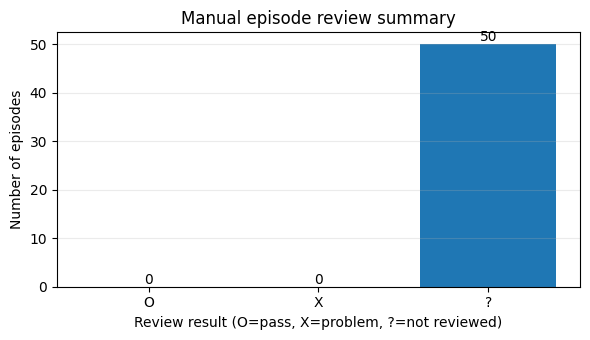

검수 결과 집계: {'O': 0, 'X': 0, '?': 50}


In [11]:
if "review_df" in globals() and not review_df.empty:
    review_counts = review_df["result"].value_counts().reindex(["O", "X", "?"], fill_value=0)
    plt.figure(figsize=(6, 3.5))
    bars = plt.bar(review_counts.index, review_counts.values)
    plt.title("Manual episode review summary")
    plt.xlabel("Review result (O=pass, X=problem, ?=not reviewed)")
    plt.ylabel("Number of episodes")
    plt.grid(axis="y", alpha=0.25)
    for bar, count in zip(bars, review_counts.values):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), str(int(count)), ha="center", va="bottom")
    plt.tight_layout()
    plt.show()
    print("검수 결과 집계:", review_counts.to_dict())
else:
    print("먼저 검수표 셀을 실행하세요.")

## 3-2. 재녹화 및 수집 과정 특이사항

이번 대화에서 확인된 이슈는 USB 시리얼 통신 문제, 초기 카메라 번호 오인(인덱스 2는 노트북 카메라), 두 대 동시 연결 시 OpenCV DSHOW/MJPG 초기화 문제였다. 문제를 해결한 뒤 최종 로컬 데이터셋에 총 50개를 저장하였다.

그러나 **어느 에피소드를 취소하거나 다시 녹화했는지**는 기록만으로 특정할 수 없다. 따라서 없는 이력을 만들어 쓰지 않고 필요 시 아래 셀에서 본인의 실제 재녹화 기록을 추가한다.


In [12]:
RERECORD_NOTES = "에피소드별 재녹화 번호·사유는 현재 확인되지 않음 (실제 기록이 있으면 기입)"
TROUBLESHOOTING_NOTES = [
    "Follower/Leader COM 포트와 모터 응답 오류를 점검하고 연결을 정상화함",
    "실제 USB 카메라가 0번과 1번임을 확인하고 2번 노트북 카메라를 제외함",
    "OpenCV DSHOW에서 해상도 → FPS → MJPG 설정 순서로 두 카메라 동시 프레임 수신을 확인함",
    "에피소드 0번 후 --resume=true로 49개를 추가하여 로컬 메타데이터 총 50개 확인함",
]
print("재녹화 이력:", RERECORD_NOTES)
print("문제 해결 기록:")
for i, note in enumerate(TROUBLESHOOTING_NOTES, 1):
    print(f" {i}. {note}")


재녹화 이력: 에피소드별 재녹화 번호·사유는 현재 확인되지 않음 (실제 기록이 있으면 기입)
문제 해결 기록:
 1. Follower/Leader COM 포트와 모터 응답 오류를 점검하고 연결을 정상화함
 2. 실제 USB 카메라가 0번과 1번임을 확인하고 2번 노트북 카메라를 제외함
 3. OpenCV DSHOW에서 해상도 → FPS → MJPG 설정 순서로 두 카메라 동시 프레임 수신을 확인함
 4. 에피소드 0번 후 --resume=true로 49개를 추가하여 로컬 메타데이터 총 50개 확인함


## 4. 실습 소감 및 후속 학습 계획

아래 소감은 실제 기록된 과정(Windows 환경 구축, 로봇 통신 점검, 카메라 설정 수정, 50개 수집)을 바탕으로 작성했다. 개별 에피소드의 성공률이나 아직 수행하지 않은 ACT 학습 성능은 **예측**과 **실측**을 구분한다.


In [13]:
REFLECTION_4_1 = (
    "Windows 환경에서 SO-101 Leader와 Follower를 연결하여 직접 시연 데이터를 수집하였다. "
    "수집 중 모터가 시리얼 포트에서 응답하지 않는 문제가 발생하여 USB 포트와 연결 상태를 다시 확인했고, "
    "카메라 인덱스 2번이 노트북 내장 카메라라는 점도 확인하여 실제 USB 카메라인 0번과 1번으로 수정하였다. "
    "또한 OpenCV에서 두 카메라를 동시에 열기 어려웠지만 해상도, FPS, MJPG 설정 순서를 조정하여 정상 프레임 수신을 확인했다. "
    "이후 첫 에피소드를 녹화한 뒤 이어서 49개를 추가하였고, 로컬 메타데이터에서 총 50개 저장을 확인했다."
)
REFLECTION_4_2 = (
    "로봇 학습 데이터는 단순히 개수를 채우는 것보다 같은 태스크를 일관된 조건에서 기록하고 카메라 시야를 안정적으로 유지하는 것이 중요하다고 느꼈다. "
    "특히 물체가 카메라 시야에서 가려지거나 집기·놓기 순간이 잘리면 행동 예측에 불리할 수 있다. "
    "ACT 모델을 학습시킬 경우 시연마다 다른 물체 시작 위치, 조명, 카메라 초점 변화가 성능에 영향을 줄 수 있다고 예상한다. "
    "따라서 후속 실습에서는 에피소드별 성공 여부를 먼저 검수하고, 학습 후 새로운 초기 위치와 환경에서도 동작을 평가할 계획이다."
)
print("4-1. 수집 과정에서 배운 점\n", REFLECTION_4_1)
print("\n4-2. 데이터 품질 및 ACT 학습 관련 고찰\n", REFLECTION_4_2)


4-1. 수집 과정에서 배운 점
 Windows 환경에서 SO-101 Leader와 Follower를 연결하여 직접 시연 데이터를 수집하였다. 수집 중 모터가 시리얼 포트에서 응답하지 않는 문제가 발생하여 USB 포트와 연결 상태를 다시 확인했고, 카메라 인덱스 2번이 노트북 내장 카메라라는 점도 확인하여 실제 USB 카메라인 0번과 1번으로 수정하였다. 또한 OpenCV에서 두 카메라를 동시에 열기 어려웠지만 해상도, FPS, MJPG 설정 순서를 조정하여 정상 프레임 수신을 확인했다. 이후 첫 에피소드를 녹화한 뒤 이어서 49개를 추가하였고, 로컬 메타데이터에서 총 50개 저장을 확인했다.

4-2. 데이터 품질 및 ACT 학습 관련 고찰
 로봇 학습 데이터는 단순히 개수를 채우는 것보다 같은 태스크를 일관된 조건에서 기록하고 카메라 시야를 안정적으로 유지하는 것이 중요하다고 느꼈다. 특히 물체가 카메라 시야에서 가려지거나 집기·놓기 순간이 잘리면 행동 예측에 불리할 수 있다. ACT 모델을 학습시킬 경우 시연마다 다른 물체 시작 위치, 조명, 카메라 초점 변화가 성능에 영향을 줄 수 있다고 예상한다. 따라서 후속 실습에서는 에피소드별 성공 여부를 먼저 검수하고, 학습 후 새로운 초기 위치와 환경에서도 동작을 평가할 계획이다.


## 5. 최종 제출 체크리스트

체크리스트는 실제 데이터와 검수 결과를 기반으로 수행한다. 로컬에 50개가 있어도 **Hub 공개, 업로드, 영상 검수**는 별도 조건으로 확인해야 한다. 미확인 항목을 자동으로 통과 처리하지 않는다.


In [14]:
review_complete = (
    isinstance(review_df, pd.DataFrame)
    and len(review_df) == EXPECTED_EPISODES
    and sorted(review_df["episode"].astype(int).tolist()) == list(range(EXPECTED_EPISODES))
    and review_df["result"].isin(["O", "X"]).all()
)
review_all_o = review_complete and review_df["result"].eq("O").all()
info_ok = bool(info) and n_ep == EXPECTED_EPISODES
cameras_ok = {"observation.images.cam0", "observation.images.cam1"}.issubset(set(camera_keys))
indices_ok = bool(ep_df is not None and "episode_index" in ep_df.columns and
                  sorted(ep_df["episode_index"].astype(int).tolist()) == list(range(EXPECTED_EPISODES)))
task_ok = bool(task_set) and task_set == {TASK}

checks = {
    "메타데이터 기준 총 50개": info_ok,
    "에피소드 번호 0~49 연속": indices_ok,
    "두 카메라 feature(cam0, cam1) 존재": cameras_ok,
    "Hub 공개 저장소 접근 및 Public 확인": hub_reachable and is_public,
    "Hub meta/info.json에서 50개 직접 확인": bool(info_source == "Hugging Face Hub" and info_ok),
    "태스크 문자열 일치": task_ok,
    "50개 전부 실제 영상 검수 완료": review_complete,
    "검수한 50개 모두 정상(O)": review_all_o,
}
for name, passed in checks.items():
    print(("[통과] " if passed else "[미확인/미흡] ") + name)
print("\n전체 조건 충족" if all(checks.values()) else "\n일부 조건이 미확인 상태입니다. 실제 영상 검수와 업로드 확인 후 완성하세요.")


[통과] 메타데이터 기준 총 50개
[통과] 에피소드 번호 0~49 연속
[통과] 두 카메라 feature(cam0, cam1) 존재
[통과] Hub 공개 저장소 접근 및 Public 확인
[통과] Hub meta/info.json에서 50개 직접 확인
[미확인/미흡] 태스크 문자열 일치
[미확인/미흡] 50개 전부 실제 영상 검수 완료
[미확인/미흡] 검수한 50개 모두 정상(O)

일부 조건이 미확인 상태입니다. 실제 영상 검수와 업로드 확인 후 완성하세요.
